In [1]:
# ── Cell 1: Install dependencies ─────────────────────────────
!pip install rdkit tqdm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 46.2 MB/s eta 0:00:00


In [2]:
# ── Cell 2: Write tensor.py ───────────────────────────────────
import os
os.makedirs('/content/src', exist_ok=True)
os.makedirs('/content/data/raw', exist_ok=True)
os.makedirs('/content/results/figures', exist_ok=True)

In [3]:
%%writefile /content/src/tensor.py
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, rdPartialCharges

GRID_SIZE  = 32
RESOLUTION = 0.5   # Angstrom per pixel

# Pauling electronegativity (normalized by 4)
EN_MAP = {
    1:0.55, 6:0.64, 7:0.76, 8:0.86, 9:1.00,
    15:0.58, 16:0.65, 17:0.74, 35:0.59, 53:0.51
}

HYBRID_MAP = {
    'S':    0.20,
    'SP':   0.33,
    'SP2':  0.66,
    'SP3':  1.00,
    'SP3D': 0.80,
}

def smiles_to_tensor(smiles, grid=GRID_SIZE, res=RESOLUTION):
    """
    Convert a SMILES string to a 7-channel MCR tensor.
    Returns: (T [7 x grid x grid], atom_positions list) or None if invalid.
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # Canonicalize for consistent atom ordering and layout
    canonical_smiles = Chem.MolToSmiles(mol, canonical=True)
    mol = Chem.MolFromSmiles(canonical_smiles)
    if mol is None:
        return None

    # Compute Gasteiger charges
    try:
        rdPartialCharges.ComputeGasteigerCharges(mol)
    except Exception:
        pass

    # Compute 2D coordinates
    AllChem.Compute2DCoords(mol)
    conf = mol.GetConformer()

    # Find centroid to center on grid
    positions_raw = []
    for atom in mol.GetAtoms():
        p = conf.GetAtomPosition(atom.GetIdx())
        positions_raw.append((p.x, p.y))

    if not positions_raw:
        return None

    cx = sum(p[0] for p in positions_raw) / len(positions_raw)
    cy = sum(p[1] for p in positions_raw) / len(positions_raw)

    T = np.zeros((7, grid, grid), dtype=np.float32)
    atom_positions = []

    for atom in mol.GetAtoms():
        p = conf.GetAtomPosition(atom.GetIdx())

        gx = int((p.x - cx) / res) + grid // 2
        gy = int((p.y - cy) / res) + grid // 2

        if not (0 <= gx < grid and 0 <= gy < grid):
            continue

        anum = atom.GetAtomicNum()

        # CH0: Atom type
        T[0, gx, gy] = min(anum / 10.0, 1.0)
        # CH1: Bond order sum
        bond_sum = sum(b.GetBondTypeAsDouble() for b in atom.GetBonds())
        T[1, gx, gy] = min(bond_sum / 4.0, 1.0)
        # CH2: Formal charge
        T[2, gx, gy] = (atom.GetFormalCharge() + 2) / 4.0
        # CH3: Aromaticity
        T[3, gx, gy] = float(atom.GetIsAromatic())
        # CH4: Electronegativity
        T[4, gx, gy] = EN_MAP.get(anum, 0.5)
        # CH5: Hybridization
        hyb_str = str(atom.GetHybridization()).split('.')[-1]
        T[5, gx, gy] = HYBRID_MAP.get(hyb_str, 0.5)
        # CH6: Gasteiger partial charge
        try:
            gc = float(atom.GetDoubleProp('_GasteigerCharge'))
            T[6, gx, gy] = np.clip((gc + 1) / 2.0, 0.0, 1.0) if np.isfinite(gc) else 0.5
        except Exception:
            T[6, gx, gy] = 0.5

        atom_positions.append((gx, gy, anum))

    return T, atom_positions


def compute_delta(smiles_reactant, smiles_product, grid=GRID_SIZE, res=RESOLUTION):
    """
    Compute the typed delta tensor between reactant and product.
    Returns: dict or None if encoding fails.
    """
    result_r = smiles_to_tensor(smiles_reactant, grid, res)
    result_p = smiles_to_tensor(smiles_product,  grid, res)

    if result_r is None or result_p is None:
        return None

    T_r, _ = result_r
    T_p, _ = result_p

    delta = {
        'atoms':  T_p[0] - T_r[0],
        'bonds':  T_p[1] - T_r[1],
        'charge': T_p[2] - T_r[2],
        'T_r':    T_r,
        'T_p':    T_p,
    }
    delta['mask'] = (
        (np.abs(delta['bonds'])  > 0.05) |
        (np.abs(delta['atoms'])  > 0.05) |
        (np.abs(delta['charge']) > 0.05)
    ).astype(np.float32)
    delta['sparsity'] = float(np.mean(delta['mask']))
    return delta


Writing /content/src/tensor.py


In [4]:
# ── Cell 3: Download USPTO dataset ───────────────────────────
import os
import pandas as pd

DATA_PATH = '/content/data/raw/uspto_train.csv'

# Try multiple reliable sources
URLS = [
    # MIT USPTO 50k from retrosim repo (tab-separated, has reactants/products)
    'https://raw.githubusercontent.com/connorcoley/retrosim/master/retrosim/data/data_processed.csv',
    # Backup: Schneider 50k reactions
    'https://raw.githubusercontent.com/rxn4chemistry/rxnmapper/main/tests/test_data/uspto_rxn_n100.csv',
]

downloaded = False
for url in URLS:
    print(f'Trying: {url}')
    ret = os.system(f'wget -q "{url}" -O "{DATA_PATH}"')
    if ret == 0:
        try:
            # Try comma first, then tab
            for sep in [',', '\t']:
                try:
                    df_test = pd.read_csv(DATA_PATH, sep=sep, nrows=5)
                    if len(df_test.columns) > 1:
                        print(f'Downloaded successfully. Columns: {df_test.columns.tolist()}')
                        downloaded = True
                        break
                except Exception:
                    continue
            if downloaded:
                break
        except Exception as e:
            print(f'  Parse failed: {e}')

if not downloaded:
    print('All downloads failed — generating synthetic SMILES dataset as fallback...')
    # Curated set of drug-like molecules covering diverse chemistry
    synthetic_smiles = [
        'CC(=O)Oc1ccccc1C(=O)O', 'CC12CCC3C(C1CCC2O)CCC4=CC(=O)CCC34C',
        'c1ccc2c(c1)ccc1ccccc12', 'CC(C)Cc1ccc(cc1)C(C)C(=O)O',
        'OC(=O)c1ccccc1O', 'CC(=O)NC1=CC=C(O)C=C1',
        'c1ccc(cc1)N', 'CC(=O)O', 'c1ccccc1', 'CCO',
        'OC(=O)CC(O)(CC(=O)O)C(=O)O', 'CC1=CC=CC=C1',
        'c1ccc(cc1)C(=O)O', 'CCCC', 'CC(N)=O',
        'OCC(O)C(O)C(O)CO', 'c1ccncc1', 'CCCCO',
        'CC(=O)c1ccccc1', 'c1ccc(cc1)Cl',
        'Nc1ccccc1', 'CC(=O)OCC', 'CCOC(=O)c1ccccc1',
        'c1ccc2[nH]ccc2c1', 'CC1CCCCC1',
        'OC1=CC=CC=C1', 'CC(C)(C)O', 'c1ccoc1',
        'CCCC(=O)O', 'c1ccc(cc1)O',
    ] * 40  # repeat to get 1200 samples
    df_synth = pd.DataFrame({'products': synthetic_smiles})
    df_synth.to_csv(DATA_PATH, index=False)
    print(f'Synthetic dataset created: {len(df_synth)} rows')

# Load and inspect
for sep in [',', '\t']:
    try:
        df = pd.read_csv(DATA_PATH, sep=sep)
        if len(df.columns) > 0:
            break
    except Exception:
        continue

print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
print(df.head(2))

Trying: https://raw.githubusercontent.com/connorcoley/retrosim/master/retrosim/data/data_processed.csv
Downloaded successfully. Columns: ['Unnamed: 0', 'class', 'id', 'prod_smiles', 'rxn_smiles', 'prod_smiles_pop', 'keep']
Dataset shape: (50016, 7)
Columns: ['Unnamed: 0', 'class', 'id', 'prod_smiles', 'rxn_smiles', 'prod_smiles_pop', 'keep']
   Unnamed: 0  class               id  \
0           0      6       US05849732   
1           1      2  US20120114765A1   

                                         prod_smiles  \
0  COC(=O)[C@H](CCCCN)NC(=O)Nc1cc(OC)cc(C(C)(C)C)c1O   
1  O=C(Nc1cccc2cnccc12)c1cc([N+](=O)[O-])c(Sc2c(C...   

                                          rxn_smiles  prod_smiles_pop  keep  
0  O=C(OCc1ccccc1)[NH:1][CH2:2][CH2:3][CH2:4][CH2...                1  True  
1  O[C:1](=[O:2])[c:3]1[cH:4][c:5]([N+:6](=[O:7])...                1  True  


SMILES column: "rxn_smiles"


Encoding:  83%|████████▎ | 999/1200 [00:02<00:00, 480.56it/s]


Successfully encoded: 1000 molecules
Tensor shapes — X: torch.Size([1000, 7, 32, 32]), y_atom: torch.Size([1000, 1, 32, 32]), y_bond: torch.Size([1000, 1, 32, 32])
Using device: cpu
Epoch  5  train=0.0227  val=0.0225
Epoch 10  train=0.0227  val=0.0225
Epoch 15  train=0.0227  val=0.0225
Epoch 20  train=0.0227  val=0.0225
Epoch 25  train=0.0227  val=0.0225
Epoch 30  train=0.0227  val=0.0225

Experiment A — Representation Fidelity
Atom type reconstruction:  97.6%
Bond order reconstruction: 97.6%
Target:                    >90% atom,  >85% bond

Decision: ✓ PASS — proceed to Experiment B


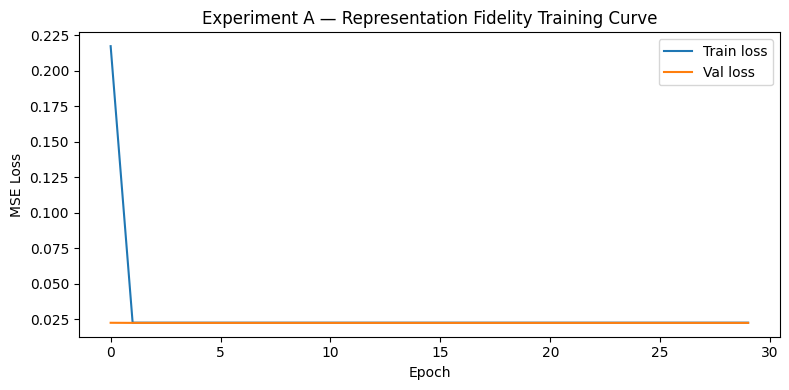

Saved: /content/results/figures/exp_A_learning_curve.png


In [5]:
# ── Cell 4: Experiment A — Representation Fidelity ────────────
import sys
sys.path.insert(0, '/content/src')

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from tensor import smiles_to_tensor
from tqdm import tqdm
import matplotlib.pyplot as plt

# ── Auto-detect SMILES column ─────────────────────────────────
SMILES_COL = None
for candidate in ['products', 'product', 'ProductSmiles',
                   'smiles', 'SMILES', 'rxn_smiles', 'reactions']:
    if candidate in df.columns:
        SMILES_COL = candidate
        break

if SMILES_COL is None:
    SMILES_COL = df.columns[-1]
    print(f'Warning: using last column as SMILES: "{SMILES_COL}"')
else:
    print(f'SMILES column: "{SMILES_COL}"')

# ── Sample and encode ─────────────────────────────────────────
sample_size = min(1200, len(df))
df_sample = df.dropna(subset=[SMILES_COL]).sample(
    sample_size, random_state=42, replace=len(df) < sample_size
)

tensors, atom_labels, bond_labels = [], [], []

for _, row in tqdm(df_sample.iterrows(), total=len(df_sample), desc='Encoding'):
    smiles = str(row[SMILES_COL])
    # For reaction SMILES (contain >>), use the product part only
    if '>>' in smiles:
        smiles = smiles.split('>>')[-1].strip()
    # For multi-component SMILES, use the first component
    smiles = smiles.split('.')[0].strip()

    result = smiles_to_tensor(smiles)
    if result is None:
        continue

    T, _ = result
    tensors.append(T)
    atom_labels.append(T[0].copy())   # CH0: atom type
    bond_labels.append(T[1].copy())   # CH1: bond order

    if len(tensors) >= 1000:
        break

print(f'Successfully encoded: {len(tensors)} molecules')
assert len(tensors) >= 100, 'Too few molecules encoded — check SMILES column'

X      = torch.tensor(np.stack(tensors),     dtype=torch.float32)
y_atom = torch.tensor(np.stack(atom_labels), dtype=torch.float32).unsqueeze(1)
y_bond = torch.tensor(np.stack(bond_labels), dtype=torch.float32).unsqueeze(1)
print(f'Tensor shapes — X: {X.shape}, y_atom: {y_atom.shape}, y_bond: {y_bond.shape}')

# ── Autoencoder ───────────────────────────────────────────────
class TensorAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(7, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                        # 16x16
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        )
        self.decoder_atom = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 2, stride=2),  # 32x32
            nn.ReLU(),
            nn.Conv2d(64, 1, 1), nn.Sigmoid()
        )
        self.decoder_bond = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 2, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 1, 1), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder_atom(z), self.decoder_bond(z)

# ── Train ─────────────────────────────────────────────────────
n = len(tensors)
split = int(n * 0.8)
dataset_train = TensorDataset(X[:split], y_atom[:split], y_bond[:split])
dataset_val   = TensorDataset(X[split:], y_atom[split:], y_bond[split:])

loader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
loader_val   = DataLoader(dataset_val,   batch_size=32)

device  = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

model   = TensorAutoencoder().to(device)
optim   = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

train_losses, val_losses = [], []

for epoch in range(30):
    model.train()
    epoch_loss = 0
    for Xb, ya, yb in loader_train:
        Xb, ya, yb = Xb.to(device), ya.to(device), yb.to(device)
        pa, pb = model(Xb)
        loss = loss_fn(pa, ya) + loss_fn(pb, yb)
        optim.zero_grad(); loss.backward(); optim.step()
        epoch_loss += loss.item()
    train_losses.append(epoch_loss / len(loader_train))

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for Xb, ya, yb in loader_val:
            Xb, ya, yb = Xb.to(device), ya.to(device), yb.to(device)
            pa, pb = model(Xb)
            val_loss += (loss_fn(pa, ya) + loss_fn(pb, yb)).item()
    val_losses.append(val_loss / len(loader_val))

    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1:2d}  train={train_losses[-1]:.4f}  val={val_losses[-1]:.4f}')

# ── Evaluate ──────────────────────────────────────────────────
model.eval()
threshold = 0.1
atom_correct, bond_correct, total = 0, 0, 0

with torch.no_grad():
    for Xb, ya, yb in loader_val:
        Xb, ya, yb = Xb.to(device), ya.to(device), yb.to(device)
        pa, pb = model(Xb)
        atom_correct += ((pa > threshold) == (ya > threshold)).float().mean().item() * len(Xb)
        bond_correct += ((pb > threshold) == (yb > threshold)).float().mean().item() * len(Xb)
        total += len(Xb)

atom_acc = atom_correct / total
bond_acc = bond_correct / total

print(f"\n{'='*40}")
print(f'Experiment A — Representation Fidelity')
print(f"{'='*40}")
print(f'Atom type reconstruction:  {atom_acc:.1%}')
print(f'Bond order reconstruction: {bond_acc:.1%}')
print(f'Target:                    >90% atom,  >85% bond')

gate = '✓ PASS — proceed to Experiment B' if atom_acc > 0.90 and bond_acc > 0.85 else '✗ Redesign tensor channels'
print(f'\nDecision: {gate}')

# ── Plot ──────────────────────────────────────────────────────
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses,   label='Val loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('Experiment A — Representation Fidelity Training Curve')
plt.legend(); plt.tight_layout()
plt.savefig('/content/results/figures/exp_A_learning_curve.png', dpi=150)
plt.show()
print('Saved: /content/results/figures/exp_A_learning_curve.png')